# Weighted Stable Garden: model, inspect, improve

This optional activity takes about five minutes. **Submit only `solver.py`**;
this notebook adds no deliverable. Read **README.txt** or the Submission
Instructions PDF for the complete rules and grading contract.

1. **Predict:** will a narrow strip, separated rooms, or a high-weight patch help your strategy?
2. **Inspect:** choose a preset; gray cells are blocked, colors show weights.
3. **Observe:** press **Run saved solver.py** to compare your checked board with a public witness.
4. **Explain:** identify one difference and one change worth trying.

Changing a preset only draws it. Search runs on a button press, under the same
three-second search / ten-second import limits as the grader. A public target is
a reachable comparison value, not a promised grade or proof of an optimum.


In [1]:
from pathlib import Path
import sys

FORCE_STATIC = False  # Set True if your notebook frontend does not render controls.
GARDEN = Path.cwd()
if not (GARDEN / 'solver.py').is_file():
    raise FileNotFoundError('Open this notebook from the folder containing solver.py.')
sys.path.insert(0, str(GARDEN.resolve()))
import problem
import test_local
catalog = test_local.catalog()
for i, entry in enumerate(catalog, 1):
    c = entry['instance']
    print(f"{i}. {entry['name']}: {c['height']} x {c['width']}")


1. one cell: 1 x 1
2. one row: 1 x 5
3. four-cell block: 2 x 2
4. six-cell still life: 3 x 3
5. outside-birth boundary check: 4 x 4
6. blocked corner: 4 x 4
7. weighted tiny board: 3 x 3
8. all blocked: 3 x 3
9. control_scattered 1: 18 x 20
10. control_bands 1: 18 x 20
11. long_strip 1: 36 x 4
12. open_square 1: 20 x 24
13. irregular_islands 1: 20 x 18
14. thin_walls 1: 18 x 20
15. connected_rooms 1: 20 x 18
16. hotspots 1: 18 x 20
17. wider_strip 1: 36 x 6
18. mixed_components 1: 30 x 26


## The rules include dead cells

A live cell must have two or three live neighbors. A dead cell must **not** have
exactly three. This applies to blocked cells and the surrounding outside ring.
The four live cells of a 2×2 block each have three neighbors; nearby dead cells
have at most two. Add weights to express which legal pattern is most valuable.

**Predict:** why would checking only the live cells miss an illegal pattern?


four-cell block — Exhaustive tiny optimum
Checked public witness value: 4


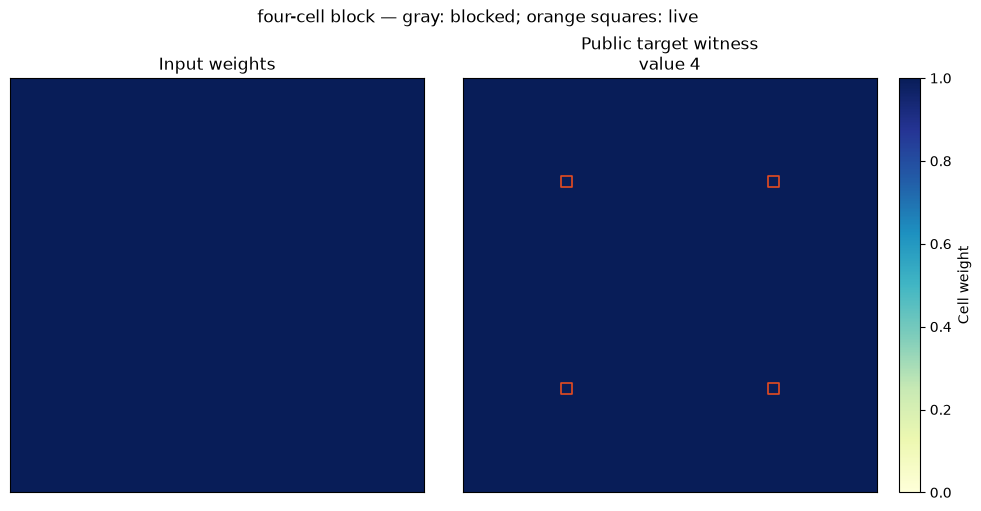

In [2]:
def inspect_case(index=18, run_solver=False):
    entry = catalog[index - 1]
    if run_solver:
        return test_local.run_case(entry, GARDEN / 'solver.py', 3.0, 7, draw=True)
    print(entry['name'], '—', entry['meaning'])
    print('Checked public witness value:', entry['target_value'])
    test_local.draw(entry, None)

inspect_case(3)  # Stable four-cell block; drawing performs no search.


## A tiny worked Z3 model

The supplied `z3_example.py` is a complete model of the open **3×3** example.
It includes dead cells and the outside ring. Each SAT result is a checked
witness; asking for a strictly better value and getting UNSAT proves the
incumbent optimal. **Unknown does not prove infeasibility or optimality.**

This small calculation runs automatically. It is not a general weighted solver.


In [4]:
from z3_example import example
board, score, status = example()
print('Tiny 3x3 value:', score, '—', status)
for row in board:
    print(' '.join(map(str, row)))


ModuleNotFoundError: No module named 'z3'

## Compare your saved file

Orange outlines mark live cells. Use one preset and one run; no screenshots or
code edits are required for this exploration. The starter often leaves a gap
because it only places 2×2 blocks. Save any edits to `solver.py` before running.

**Predict:** when blocked rows or columns divide a garden into rooms, can the
rooms be solved separately and combined? Decide what the stability rules say
before you trust such a split, and check every whole board you build.

**Optional bonus practice:** `python3 test_local.py --bonus` checks exact results
on small gardens built from rooms, for up to five bonus points. Use
`--bonus --case 1 --draw` to inspect one public example, or add
`--final` for more cases. These structured targets are exact optima; the ordinary
large-board comparison targets are reachable witnesses. The same three-second
total search allowance and single `solver.py` submission apply.


In [ ]:
try:
    if FORCE_STATIC:
        raise ImportError('Static mode requested')
    import ipywidgets as widgets
    from IPython.display import display
except ImportError:
    print('Static mode: inspect_case(18, run_solver=True) runs your file once.')
    print('The equivalent CLI is: python3 test_local.py --case 18 --compare')
    inspect_case(18)
else:
    preset = widgets.Dropdown(options=[(e['name'], i) for i,e in enumerate(catalog,1)],
                              value=18, description='Preset:',
                              layout=widgets.Layout(width='auto', align_self='stretch', margin='0px'))
    button = widgets.Button(description='Run saved solver.py', button_style='primary')
    output = widgets.Output(layout=widgets.Layout(width='auto', margin='0px', min_width='0px'))
    def show_preset(change):
        with output:
            output.clear_output(wait=True)
            inspect_case(preset.value)
    def run_saved(_):
        button.disabled = True
        try:
            with output:
                output.clear_output(wait=True)
                inspect_case(preset.value, run_solver=True)
        finally:
            button.disabled = False
    preset.observe(show_preset, names='value')
    button.on_click(run_saved)
    display(widgets.VBox([preset, button, output], layout=widgets.Layout(width='100%', margin='0px')))
    show_preset(None)


## Reflection and optional deeper work

- Which rule rejected a candidate or limited the pattern you expected?
- Where is there unused weight, and what would you try to change?
- Which conclusion is justified: a legal witness, matching a public target, or a proved optimum?

Optional ideas: model a bounded patch with the rest fixed; choose variable or
patch order using weights; compare narrow and wider strips; look at what happens
where rooms meet. Leave enough time to save a valid incumbent with `budget.offer`.
Do not interpret a Z3 timeout as UNSAT.

Text feedback remains available without plots or widgets:
`python3 test_local.py --list`, `python3 test_local.py --case 18 --compare`,
and `python3 test_local.py --final --compare`.
